# EDA: how do failures change over time?

In this notebook I use the cleaned data from notebook 01 (446 sensors, 1,567 samples).
First I look at the fail rate over time, then at which sensors differ between passed and failed samples.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/secom_clean.csv", parse_dates=["timestamp"])
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]

print(df.shape)
print(df["label"].value_counts())

(1567, 448)
label
-1    1463
 1     104
Name: count, dtype: int64


In [4]:
# weekly number of samples and failures
weekly = (df.set_index("timestamp")
            .resample("W")["label"]
            .agg(n_samples="count", n_fails=lambda s: (s == 1).sum()))
weekly["fail_rate"] = weekly["n_fails"] / weekly["n_samples"]
print(weekly.round(3))

            n_samples  n_fails  fail_rate
timestamp                                
2008-07-20         13        3      0.231
2008-07-27         21        2      0.095
2008-08-03         48       10      0.208
2008-08-10        108       14      0.130
2008-08-17         51        7      0.137
2008-08-24        208       22      0.106
2008-08-31        169        7      0.041
2008-09-07        133        2      0.015
2008-09-14         95        4      0.042
2008-09-21        154        5      0.032
2008-09-28        166        4      0.024
2008-10-05        169       15      0.089
2008-10-12        138        8      0.058
2008-10-19         94        1      0.011


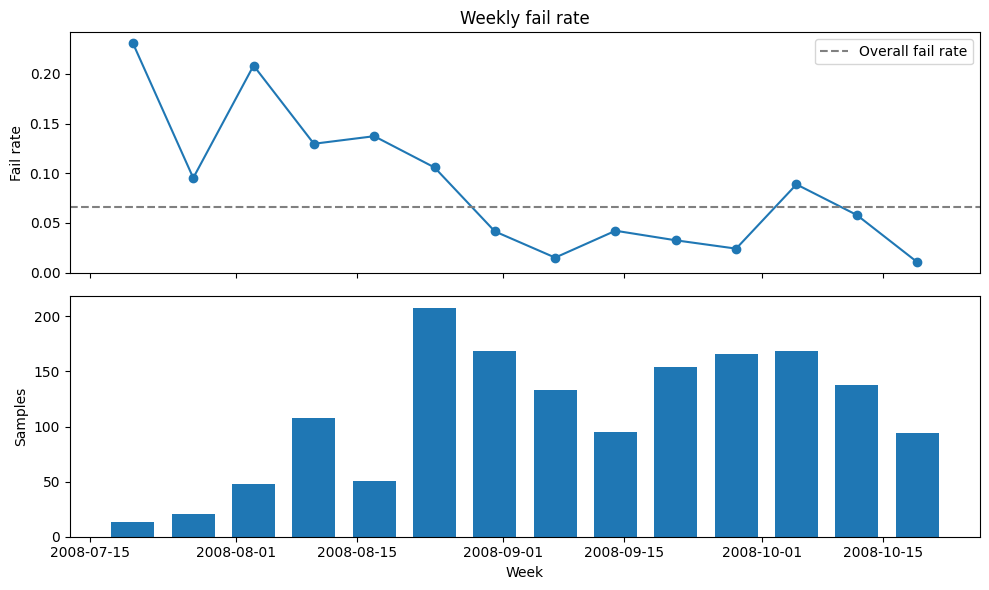

In [5]:
overall_rate = (df["label"] == 1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# top: weekly fail rate
axes[0].plot(weekly.index, weekly["fail_rate"], marker="o")
axes[0].axhline(overall_rate, color="gray", linestyle="--", label="Overall fail rate")
axes[0].set_ylabel("Fail rate")
axes[0].set_title("Weekly fail rate")
axes[0].legend()

# bottom: how many samples each week
axes[1].bar(weekly.index, weekly["n_samples"], width=5)
axes[1].set_ylabel("Samples")
axes[1].set_xlabel("Week")

plt.tight_layout()
plt.show()

## Fail rate over time
The fail rate was high in July and August, around 10-20% in most weeks. After late August it dropped to
about 1-6%. The first three weeks only have 13, 21 and 48 samples, so those points jump around a lot
and I don't trust them much. The overall fail rate is 6.6% (dashed line).

In [6]:
# compare fail rate before and after the cutoff date
from scipy.stats import chi2_contingency

cutoff = pd.Timestamp("2008-08-25")
early = df[df["timestamp"] < cutoff]
late = df[df["timestamp"] >= cutoff]

for name, part in [("early", early), ("late", late)]:
    print(name, "samples:", len(part), "fails:", (part["label"] == 1).sum(),
          "fail rate:", round((part["label"] == 1).mean(), 3))

# chi-square test: is the difference likely just luck?
table = [[(early["label"] == 1).sum(), (early["label"] == -1).sum()],
         [(late["label"] == 1).sum(), (late["label"] == -1).sum()]]
chi2, p, _, _ = chi2_contingency(table)
print("p-value:", p)

early samples: 449 fails: 58 fail rate: 0.129
late samples: 1118 fails: 46 fail rate: 0.041
p-value: 5.055728943908669e-10


### Is the drop real?
I split the data at the end of August. Before: 449 samples, 12.9% failed. After: 1,118 samples, 4.1% failed.
The p-value from a chi-square test is about 5e-10, so this big a gap is very unlikely to be just luck.
I don't know why it dropped. It could be a process change, different products, or a change in how
samples were checked. I would need to ask an engineer.

This matters for modeling: if I split the data randomly, the training and test sets will mix early
and late samples. I also want to try splitting by time (train on early, test on late).

In [7]:
# daily samples and fails in the week with the spike (Sep 29 to Oct 5)
spike = df[(df["timestamp"] >= "2008-09-29") & (df["timestamp"] < "2008-10-06")]
daily = (spike.set_index("timestamp")
              .resample("D")["label"]
              .agg(n_samples="count", n_fails=lambda s: (s == 1).sum()))
daily["fail_rate"] = (daily["n_fails"] / daily["n_samples"]).round(3)
print(daily)

            n_samples  n_fails  fail_rate
timestamp                                
2008-09-29         21        1      0.048
2008-09-30         21        1      0.048
2008-10-01         17        1      0.059
2008-10-02         35        5      0.143
2008-10-03         25        0      0.000
2008-10-04         18        1      0.056
2008-10-05         32        6      0.188


### The spike in early October
The week of Oct 5 had 15 failures out of 169 samples. Most of them came from two days: Oct 2 (5 out of 35)
and Oct 5 (6 out of 32). Oct 3 had none. So it looks like two bad days, not a bad week.
But I'm looking at about 90 days and picking the worst ones, so some extreme days are expected by chance.
I treat this as a lead to check, not a finding.